# 02 · Pasco COVID cases

**Requirement 2 · 5 points · two lines**

The daily series reveals short-term variation; the moving average makes the longer trend easier to follow. Two lines show how smoothing changes the signal. Both series use one cases-per-day axis; a second axis would give identical units different visual scales.

**Source:** `data/Combined.xlsx`, `Pasco` worksheet. Dates are event dates, not download dates. These are raw case counts, not population-adjusted comparisons.

**Source-specific detail:** the supplied average reproduces an **8-observation trailing mean**, current observation included, with partial initial windows. Hillsborough matches exactly; Pasco differs by no more than 0.05 because of displayed one-decimal rounding. It is not relabeled as a 7-day average.

Daily dates absent from the sheet are reintroduced as **missing**, not zero. The original supplied average stays unchanged; the displayed lines have gaps for unlisted dates.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'config').is_dir() else Path.cwd().parent
assert (ROOT / 'config/assignment.json').is_file(), 'Open from the repository or notebooks directory.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from dv_assignment.data import config
from dv_assignment.data import course_county
from dv_assignment import charts


## Load and validate the actual course worksheet

The loader checks dates, duplicate keys, numeric values, and every supplied moving average against its observed source formula. The code is in `dv_assignment/data.py`; the plotting code is in `dv_assignment/charts.py`.

In [2]:
data = course_county(config()['covid'], 'Pasco')
print(data.attrs)
display(data.head(12))
print(f"Observed days: {data.daily_cases.notna().sum():,}")
print(f"Cases across listed dates: {data.daily_cases.sum():,.0f}")
print(f"Unlisted calendar dates: {data.attrs['missing_calendar_days']}")

{'county': 'Pasco', 'state': 'Florida', 'average_definition': 'Supplied 8-observation trailing average', 'missing_calendar_days': 4, 'average_supplied': True, 'negative_daily_revisions': 0, 'source': 'Combined.xlsx', 'average_validation': 'All supplied values reproduced within source rounding precision'}


,daily_cases,moving_average
date,,
2020-03-01,2.0,2.0
2020-03-02,1.0,1.5
2020-03-03,NaN,NaN
2020-03-04,NaN,NaN
2020-03-05,NaN,NaN
2020-03-06,NaN,NaN
2020-03-07,2.0,1.7
2020-03-08,3.0,2.0
2020-03-09,5.0,2.6


Observed days: 367
Cases across listed dates: 34,047
Unlisted calendar dates: 4


## Required visualization

Blue and orange separate the series with strong contrast. The source note defines the moving average, the y-axis starts at zero, and date ticks remain readable across the complete period.

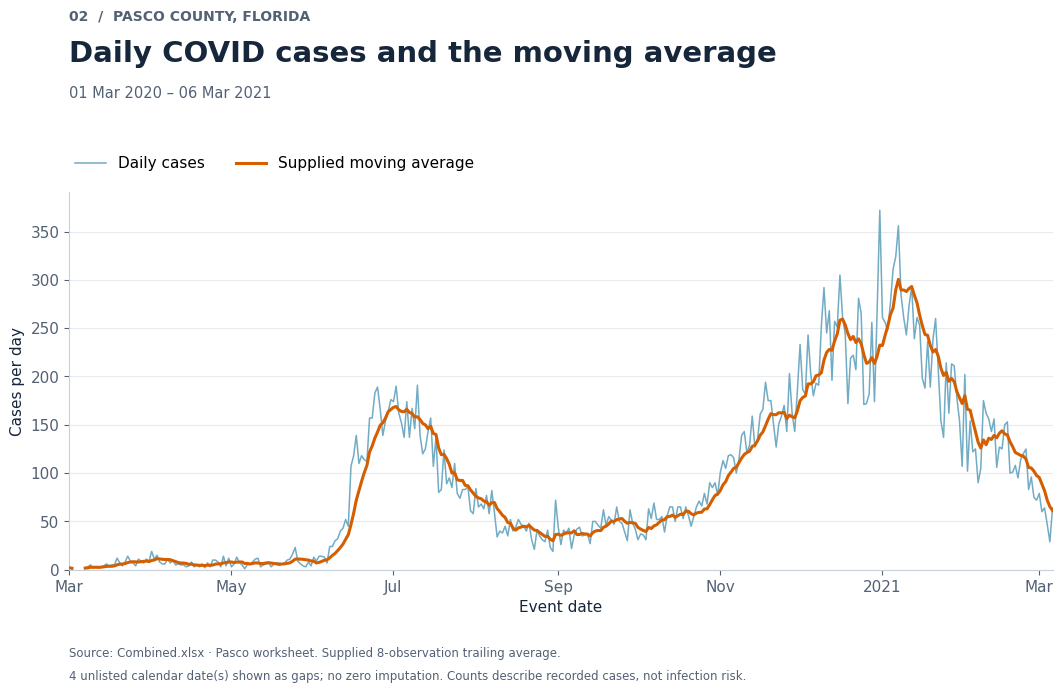

In [3]:
fig = charts.pasco(data)
charts.export(fig, ROOT / 'figures', '02_pasco_covid')
plt.show()

## Read the result

Use the table below to verify the highest recorded day and peak supplied average. The moving average smooths recorded variation; it is not a forecast. Missing dates are not evidence of zero cases. Changes in testing and case recording can affect the daily series.

In [4]:
print(f"Highest recorded daily count: {data.daily_cases.max():,.0f} on {data.daily_cases.idxmax():%d %b %Y}")
print(f"Highest supplied moving average: {data.moving_average.max():,.1f} on {data.moving_average.idxmax():%d %b %Y}")

Highest recorded daily count: 372 on 31 Dec 2020
Highest supplied moving average: 300.5 on 07 Jan 2021
